In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
df = pd.read_excel("/Users/temaka/PycharmProjects/S2ModeladoMatematico/observaciones_02_03_2026.xlsx")
fecha = pd.to_datetime(df["fecha"].dropna())
estacion_temp = df["estacion_temp"].dropna()
sensor_temp = df["sensor_temp"].dropna()
print("Número de observaciones:", len(fecha))

Número de observaciones: 289


In [3]:
datos = pd.DataFrame({
    "fecha": fecha,
    "sensor_temp": sensor_temp,
})

# Establecer fecha como índice
datos = datos.set_index('fecha')
datos.head()

,sensor_temp
fecha,
2026-10-02 14:24:52,23.1
2026-10-02 14:29:52,24.1
2026-10-02 14:34:52,23.9
2026-10-02 14:39:52,23.5
2026-10-02 14:44:52,25.9


Periodo estacional utilizado:
m = 12 observaciones

DIVISIÓN DEL DATASET
Total de observaciones : 289
Entrenamiento          : 231
Prueba                 : 58

Periodo entrenamiento:
2026-10-02 14:24:52 -> 2026-10-03 09:34:53

Periodo prueba:
2026-10-03 09:39:54 -> 2026-10-03 14:24:55

TEMPERATURA


,Modelo,MAE,RMSE,MAPE (%),R2
0,Average,0.9396,1.1605,6.1957,-1.6903
1,Naive,1.0034,1.2166,6.2118,-1.9566
2,Seasonal_Naive,1.2207,1.4134,7.5952,-2.9905
3,Drift,2.0711,2.4466,12.8548,-10.9582



COMPARACIÓN GENERAL


,Variable,Modelo,MAE,RMSE,MAPE (%),R2
0,Temperatura,Average,0.9396,1.1605,6.1957,-1.6903
1,Temperatura,Naive,1.0034,1.2166,6.2118,-1.9566
2,Temperatura,Seasonal_Naive,1.2207,1.4134,7.5952,-2.9905
3,Temperatura,Drift,2.0711,2.4466,12.8548,-10.9582



MEJOR MODELO SEGÚN RMSE

Temperatura: Average
RMSE = 1.1605
MAE  = 0.9396
MAPE = 6.1957 %
R²   = -1.6903


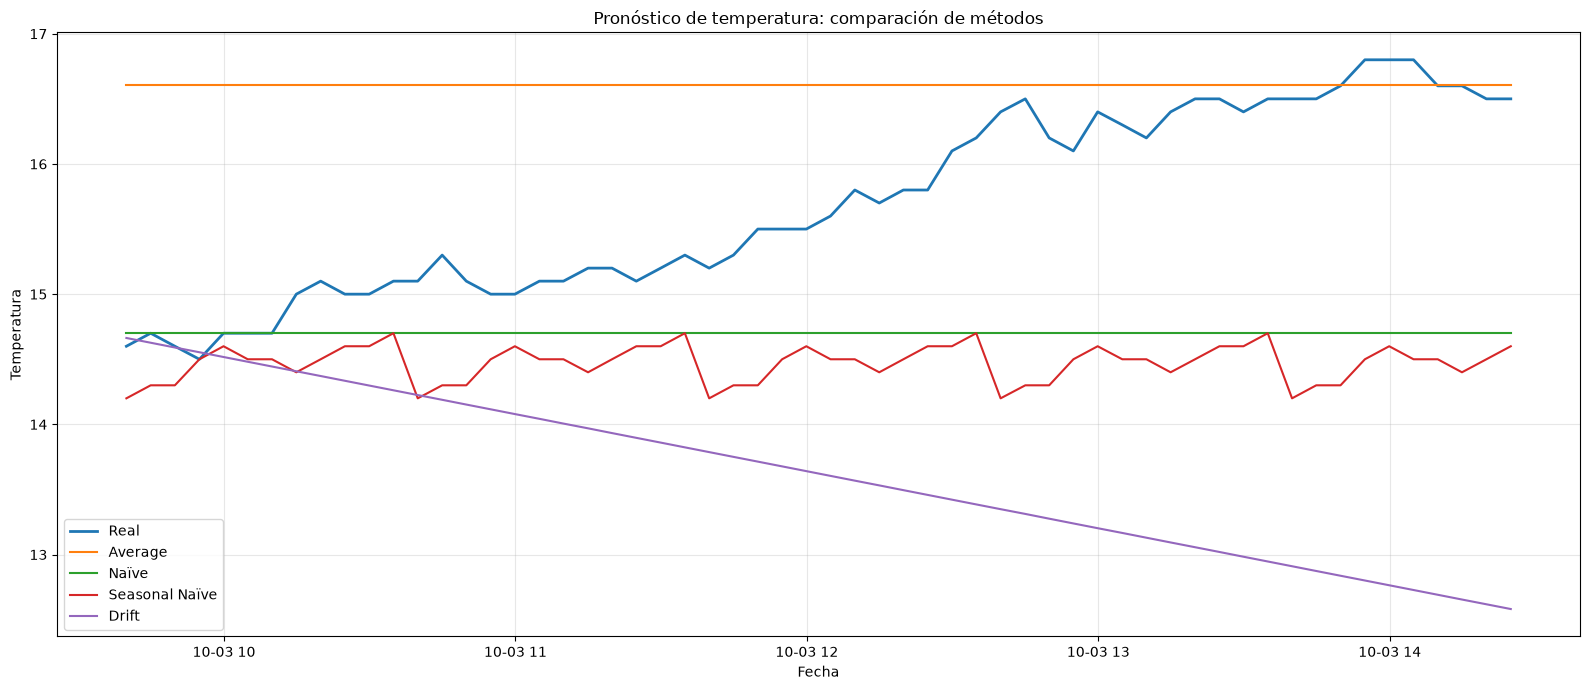

In [8]:
# ================================================================
# COMPARACIÓN DE MÉTODOS BÁSICOS DE PRONÓSTICO
#
# 1. Average
# 2. Naïve
# 3. Seasonal Naïve
# 4. Drift
#
# Variables:
#   tempAvg      -> Temperatura
#   humidityAvg  -> Humedad relativa
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

m = 12
print("Periodo estacional utilizado:")
print(f"m = {m} observaciones")


# ================================================================
# 2. DIVISIÓN CRONOLÓGICA 80/20
# ================================================================

n = len(datos)

n_train = int(0.80 * n)

train = datos.iloc[:n_train].copy()
test  = datos.iloc[n_train:].copy()

print("\n==============================================")
print("DIVISIÓN DEL DATASET")
print("==============================================")

print(f"Total de observaciones : {n}")
print(f"Entrenamiento          : {len(train)}")
print(f"Prueba                 : {len(test)}")

print("\nPeriodo entrenamiento:")
print(train.index.min(), "->", train.index.max())

print("\nPeriodo prueba:")
print(test.index.min(), "->", test.index.max())


# ================================================================
# 3. MÉTODO AVERAGE
# ================================================================

def average_forecast(y_train, h):

    media = y_train.mean()

    return np.repeat(media, h)


# ================================================================
# 4. MÉTODO NAÏVE
# ================================================================

def naive_forecast(y_train, h):

    ultimo = y_train.iloc[-1]

    return np.repeat(ultimo, h)


# ================================================================
# 5. MÉTODO SEASONAL NAÏVE
# ================================================================

def seasonal_naive_forecast(y_train, h, m):

    if len(y_train) < m:
        raise ValueError(
            "No existen suficientes observaciones "
            "para completar un periodo estacional."
        )

    ultima_temporada = y_train.iloc[-m:].to_numpy()

    pronostico = np.resize(
        ultima_temporada,
        h
    )

    return pronostico


# ================================================================
# 6. MÉTODO DRIFT
# ================================================================

def drift_forecast(y_train, h):

    y1 = y_train.iloc[0]
    yT = y_train.iloc[-1]

    T = len(y_train)

    pendiente = (yT - y1) / (T - 1)

    pasos = np.arange(1, h + 1)

    pronostico = (
        yT +
        pasos * pendiente
    )

    return pronostico


# ================================================================
# 7. MÉTRICAS
# ================================================================

def metricas(real, pred):

    real = np.asarray(real)
    pred = np.asarray(pred)

    mae = mean_absolute_error(
        real,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            real,
            pred
        )
    )

    r2 = r2_score(
        real,
        pred
    )

    # -----------------------------------------------
    # MAPE
    # -----------------------------------------------

    mascara = real != 0

    if np.any(mascara):

        mape = (
            np.mean(
                np.abs(
                    (real[mascara] - pred[mascara])
                    / real[mascara]
                )
            )
            * 100
        )

    else:

        mape = np.nan

    return mae, rmse, mape, r2


# ================================================================
# 8. FUNCIÓN GENERAL DE EVALUACIÓN
# ================================================================

def evaluar_modelos(
    train,
    test,
    variable,
    m
):

    y_train = train[variable]
    y_test = test[variable]

    h = len(y_test)

    # -----------------------------------------------
    # Pronósticos
    # -----------------------------------------------

    pred_average = average_forecast(
        y_train,
        h
    )

    pred_naive = naive_forecast(
        y_train,
        h
    )

    pred_snaive = seasonal_naive_forecast(
        y_train,
        h,
        m
    )

    pred_drift = drift_forecast(
        y_train,
        h
    )

    # -----------------------------------------------
    # DataFrame de resultados
    # -----------------------------------------------

    predicciones = pd.DataFrame(
        {
            "Real": y_test.to_numpy(),

            "Average":
                pred_average,

            "Naive":
                pred_naive,

            "Seasonal_Naive":
                pred_snaive,

            "Drift":
                pred_drift
        },

        index=y_test.index
    )

    # -----------------------------------------------
    # Calcular métricas
    # -----------------------------------------------

    resultados = []

    modelos = [
        "Average",
        "Naive",
        "Seasonal_Naive",
        "Drift"
    ]

    for modelo in modelos:

        mae, rmse, mape, r2 = metricas(
            predicciones["Real"],
            predicciones[modelo]
        )

        resultados.append(
            {
                "Modelo": modelo,
                "MAE": mae,
                "RMSE": rmse,
                "MAPE (%)": mape,
                "R2": r2
            }
        )

    tabla = pd.DataFrame(resultados)

    return predicciones, tabla


# ================================================================
# 9. EVALUACIÓN DE TEMPERATURA
# ================================================================

pred_temp, met_temp = evaluar_modelos(
    train,
    test,
    "sensor_temp",
    m
)

met_temp["Variable"] = "Temperatura"


print("\n==============================================")
print("TEMPERATURA")
print("==============================================")

display(
    met_temp[
        [
            "Modelo",
            "MAE",
            "RMSE",
            "MAPE (%)",
            "R2"
        ]
    ].round(4)
)


# ================================================================
# 11. TABLA GENERAL
# ================================================================

comparacion = pd.concat(
    [
        met_temp,
    ],
    ignore_index=True
)

comparacion = comparacion[
    [
        "Variable",
        "Modelo",
        "MAE",
        "RMSE",
        "MAPE (%)",
        "R2"
    ]
]


print("\n==============================================")
print("COMPARACIÓN GENERAL")
print("==============================================")

display(
    comparacion.round(4)
)


# ================================================================
# 12. MEJOR MODELO SEGÚN RMSE
# ================================================================

print("\n==============================================")
print("MEJOR MODELO SEGÚN RMSE")
print("==============================================")

for variable in comparacion["Variable"].unique():

    aux = comparacion[
        comparacion["Variable"] == variable
    ]

    mejor = aux.loc[
        aux["RMSE"].idxmin()
    ]

    print(
        f"\n{variable}: "
        f"{mejor['Modelo']}"
    )

    print(
        f"RMSE = {mejor['RMSE']:.4f}"
    )

    print(
        f"MAE  = {mejor['MAE']:.4f}"
    )

    print(
        f"MAPE = {mejor['MAPE (%)']:.4f} %"
    )

    print(
        f"R²   = {mejor['R2']:.4f}"
    )


# ================================================================
# 13. GRÁFICA TEMPERATURA
# ================================================================
#
# Se muestran los primeros 7 días del conjunto de prueba.
# ================================================================

n_grafica = min(
    7 * m,
    len(pred_temp)
)

plt.figure(figsize=(16,7))

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Real"].iloc[:n_grafica],
    label="Real",
    linewidth=2
)

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Average"].iloc[:n_grafica],
    label="Average"
)

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Naive"].iloc[:n_grafica],
    label="Naïve"
)

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Seasonal_Naive"].iloc[:n_grafica],
    label="Seasonal Naïve"
)

plt.plot(
    pred_temp.index[:n_grafica],
    pred_temp["Drift"].iloc[:n_grafica],
    label="Drift"
)

plt.title(
    "Pronóstico de temperatura: comparación de métodos"
)

plt.xlabel("Fecha")
plt.ylabel("Temperatura")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()